In [2]:
import pandas as pd

print("Hello Amazon Quant Project!")
print("Pandas version:", pd.__version__)

Hello Amazon Quant Project!
Pandas version: 3.1.0


In [3]:
import yfinance as yf
import pandas as pd

In [4]:
amzn = yf.download(
    "AMZN",
    start="2018-01-01",
    end="2026-01-01",
    auto_adjust=False
)

amzn.head()

c:\Users\amine mizhar\Amazon Quant Project\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\amine mizhar\Amazon Quant Project\.venv\Lib\site-packages\yfinance\utils.py:604: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  splits.set_index("date", inplace=True)
c:\Users\amine mizhar\Amazon Quant Project\.venv\Lib\site-packages\yfinance\utils.py:606: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,AMZN,AMZN,AMZN,AMZN,AMZN,AMZN
Date,,,,,,
2018-01-02,59.450500,59.450500,59.500000,58.525501,58.599998,53890000
2018-01-03,60.209999,60.209999,60.274502,59.415001,59.415001,62176000
2018-01-04,60.479500,60.479500,60.793499,60.233002,60.250000,60442000
2018-01-05,61.457001,61.457001,61.457001,60.500000,60.875500,70894000
2018-01-08,62.343498,62.343498,62.653999,61.601501,61.799999,85590000


In [5]:
amzn.shape

(2011, 6)

In [6]:
amzn.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 2011 entries, 2018-01-02 to 2025-12-31
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   (Adj Close, AMZN)  2011 non-null   float64
 1   (Close, AMZN)      2011 non-null   float64
 2   (High, AMZN)       2011 non-null   float64
 3   (Low, AMZN)        2011 non-null   float64
 4   (Open, AMZN)       2011 non-null   float64
 5   (Volume, AMZN)     2011 non-null   int64  
dtypes: float64(5), int64(1)
memory usage: 110.0 KB


In [7]:
amzn.to_csv("../data/raw/amzn_market_raw.csv")

In [8]:
amzn.shape

(2011, 6)

In [9]:
amzn.head()

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,AMZN,AMZN,AMZN,AMZN,AMZN,AMZN
Date,,,,,,
2018-01-02,59.450500,59.450500,59.500000,58.525501,58.599998,53890000
2018-01-03,60.209999,60.209999,60.274502,59.415001,59.415001,62176000
2018-01-04,60.479500,60.479500,60.793499,60.233002,60.250000,60442000
2018-01-05,61.457001,61.457001,61.457001,60.500000,60.875500,70894000
2018-01-08,62.343498,62.343498,62.653999,61.601501,61.799999,85590000


In [10]:
amzn.columns = amzn.columns.get_level_values(0)

amzn.head()

Price,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2018-01-02,59.450500,59.450500,59.500000,58.525501,58.599998,53890000
2018-01-03,60.209999,60.209999,60.274502,59.415001,59.415001,62176000
2018-01-04,60.479500,60.479500,60.793499,60.233002,60.250000,60442000
2018-01-05,61.457001,61.457001,61.457001,60.500000,60.875500,70894000
2018-01-08,62.343498,62.343498,62.653999,61.601501,61.799999,85590000


In [11]:
amzn.isnull().sum()

Price
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64

In [12]:
amzn.index

DatetimeIndex(['2018-01-02', '2018-01-03', '2018-01-04', '2018-01-05',
               '2018-01-08', '2018-01-09', '2018-01-10', '2018-01-11',
               '2018-01-12', '2018-01-16',
               ...
               '2025-12-17', '2025-12-18', '2025-12-19', '2025-12-22',
               '2025-12-23', '2025-12-24', '2025-12-26', '2025-12-29',
               '2025-12-30', '2025-12-31'],
              dtype='datetime64[s]', name='Date', length=2011, freq=None)

In [13]:
type(amzn.index)

pandas.DatetimeIndex

In [14]:
amzn_clean = amzn.copy()

amzn_clean = amzn_clean.reset_index()

amzn_clean["Date"] = pd.to_datetime(amzn_clean["Date"])

amzn_clean.to_csv(
    "../data/processed/amzn_market_clean.csv",
    index=False
)

amzn_clean.head()

Price,Date,Adj Close,Close,High,Low,Open,Volume
0,2018-01-02,59.450500,59.450500,59.500000,58.525501,58.599998,53890000
1,2018-01-03,60.209999,60.209999,60.274502,59.415001,59.415001,62176000
2,2018-01-04,60.479500,60.479500,60.793499,60.233002,60.250000,60442000
3,2018-01-05,61.457001,61.457001,61.457001,60.500000,60.875500,70894000
4,2018-01-08,62.343498,62.343498,62.653999,61.601501,61.799999,85590000


In [15]:
amzn_clean["Daily_Return"] = amzn_clean["Adj Close"].pct_change()

amzn_clean.head()

Price,Date,Adj Close,Close,High,Low,Open,Volume,Daily_Return
0,2018-01-02,59.450500,59.450500,59.500000,58.525501,58.599998,53890000,NaN
1,2018-01-03,60.209999,60.209999,60.274502,59.415001,59.415001,62176000,0.012775
2,2018-01-04,60.479500,60.479500,60.793499,60.233002,60.250000,60442000,0.004476
3,2018-01-05,61.457001,61.457001,61.457001,60.500000,60.875500,70894000,0.016163
4,2018-01-08,62.343498,62.343498,62.653999,61.601501,61.799999,85590000,0.014425


In [16]:
amzn_clean["Daily_Return"].describe()

count    2010.000000
mean        0.000910
std         0.021675
min        -0.140494
25%        -0.010237
50%         0.001082
75%         0.012252
max         0.135359
Name: Daily_Return, dtype: float64

In [17]:
amzn_clean.to_csv(
    "../data/processed/amzn_market_clean.csv",
    index=False
)

In [18]:
annual_volatility = amzn_clean["Daily_Return"].std() * (252 ** 0.5)

print("Annualized volatility:", annual_volatility)
print("Annualized volatility (%):", annual_volatility * 100)

Annualized volatility: 0.344081024487597
Annualized volatility (%): 34.4081024487597


In [19]:
amzn_clean["Cumulative_Return"] = (
    (1 + amzn_clean["Daily_Return"]).cumprod()
)

amzn_clean[["Date", "Cumulative_Return"]].head()

Price,Date,Cumulative_Return
0,2018-01-02,NaN
1,2018-01-03,1.012775
2,2018-01-04,1.017309
3,2018-01-05,1.033751
4,2018-01-08,1.048662


In [20]:
final_value = amzn_clean["Cumulative_Return"].iloc[-1]

print("Final value of $1 invested:", final_value)
print("Total return (%):", (final_value - 1) * 100)

Final value of $1 invested: 3.8825578494451816
Total return (%): 288.25578494451815


Matplotlib is building the font cache; this may take a moment.


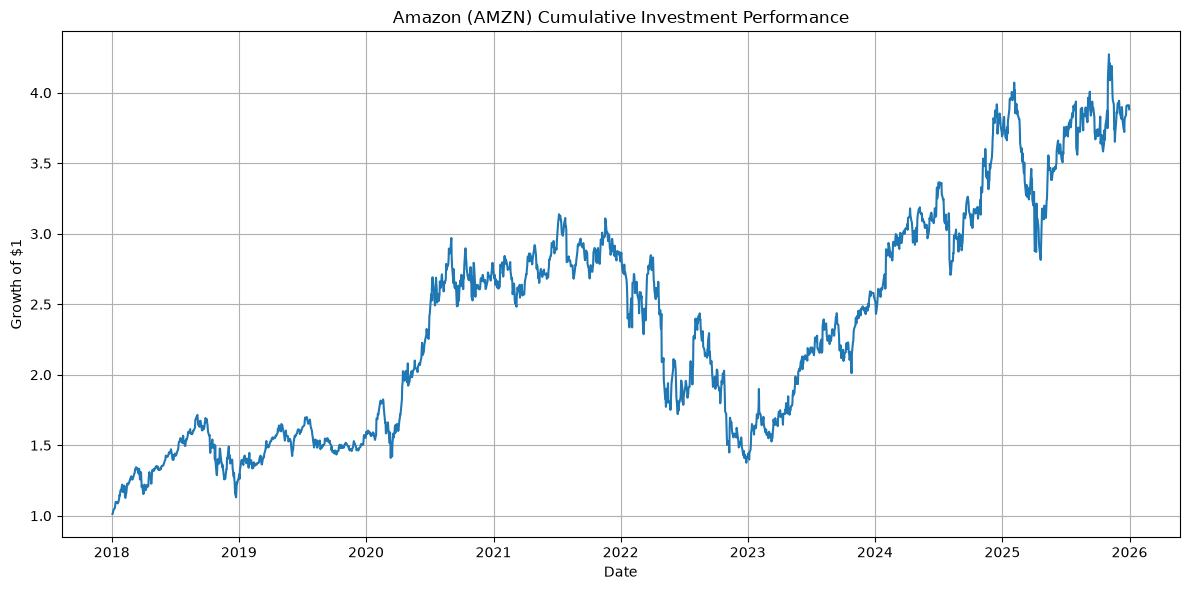

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    amzn_clean["Date"],
    amzn_clean["Cumulative_Return"]
)

plt.title("Amazon (AMZN) Cumulative Investment Performance")
plt.xlabel("Date")
plt.ylabel("Growth of $1")

plt.grid(True)
plt.tight_layout()

plt.show()

In [22]:
import yfinance as yf

sp500 = yf.download(
    "^GSPC",
    start="2018-01-01",
    end="2026-01-01",
    auto_adjust=False
)

sp500.head()

c:\Users\amine mizhar\Amazon Quant Project\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
[*********************100%***********************]  1 of 1 completed
c:\Users\amine mizhar\Amazon Quant Project\.venv\Lib\site-packages\yfinance\multi.py:220: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.rename(columns=ctx.isins, inplace=True)
c:\Users\amine mizhar\Amazon Quant Project\.venv\Lib\site-packages\yfinance\multi.py:224: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pand

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC
Date,,,,,,
2018-01-02,2695.810059,2695.810059,2695.889893,2682.360107,2683.729980,3397430000
2018-01-03,2713.060059,2713.060059,2714.370117,2697.770020,2697.850098,3544030000
2018-01-04,2723.989990,2723.989990,2729.290039,2719.070068,2719.310059,3697340000
2018-01-05,2743.149902,2743.149902,2743.449951,2727.919922,2731.330078,3239280000
2018-01-08,2747.709961,2747.709961,2748.510010,2737.600098,2742.669922,3246160000


In [23]:
sp500.columns = sp500.columns.get_level_values(0)

sp500_clean = sp500.copy()

sp500_clean = sp500_clean.reset_index()

sp500_clean["Date"] = pd.to_datetime(sp500_clean["Date"])

sp500_clean.head()

Price,Date,Adj Close,Close,High,Low,Open,Volume
0,2018-01-02,2695.810059,2695.810059,2695.889893,2682.360107,2683.729980,3397430000
1,2018-01-03,2713.060059,2713.060059,2714.370117,2697.770020,2697.850098,3544030000
2,2018-01-04,2723.989990,2723.989990,2729.290039,2719.070068,2719.310059,3697340000
3,2018-01-05,2743.149902,2743.149902,2743.449951,2727.919922,2731.330078,3239280000
4,2018-01-08,2747.709961,2747.709961,2748.510010,2737.600098,2742.669922,3246160000


In [24]:
sp500_clean["Daily_Return"] = sp500_clean["Adj Close"].pct_change()

sp500_clean["Daily_Return"].describe()

count    2010.000000
mean        0.000540
std         0.012347
min        -0.119841
25%        -0.004450
50%         0.000905
75%         0.006533
max         0.095154
Name: Daily_Return, dtype: float64

In [25]:
sp500_volatility = sp500_clean["Daily_Return"].std() * (252 ** 0.5)

print("S&P 500 annualized volatility:", sp500_volatility)
print("S&P 500 annualized volatility (%):", sp500_volatility * 100)

S&P 500 annualized volatility: 0.19600136467226792
S&P 500 annualized volatility (%): 19.600136467226793


In [26]:
sp500_clean["Cumulative_Return"] = (
    (1 + sp500_clean["Daily_Return"]).cumprod()
)

sp500_final_value = sp500_clean["Cumulative_Return"].iloc[-1]

print("Final value of $1 invested in S&P 500:", sp500_final_value)
print(
    "S&P 500 total return (%):",
    (sp500_final_value - 1) * 100
)

Final value of $1 invested in S&P 500: 2.5393109496634585
S&P 500 total return (%): 153.93109496634585


In [27]:
sp500_clean.to_csv(
    "../data/processed/sp500_market_clean.csv",
    index=False
)

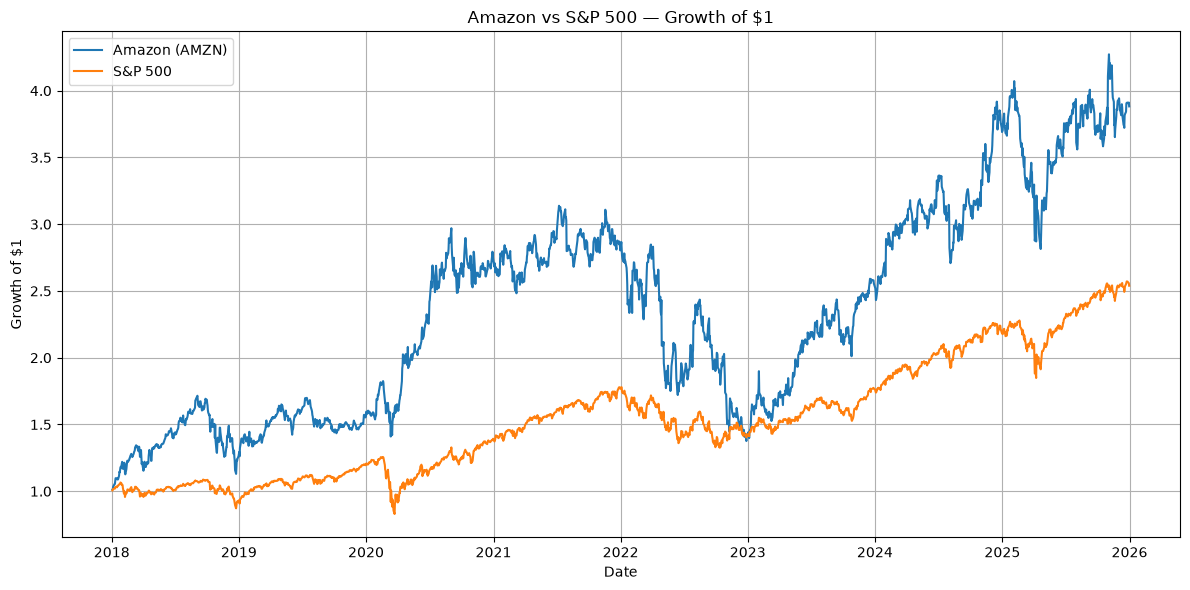

In [28]:
plt.figure(figsize=(12, 6))

plt.plot(
    amzn_clean["Date"],
    amzn_clean["Cumulative_Return"],
    label="Amazon (AMZN)"
)

plt.plot(
    sp500_clean["Date"],
    sp500_clean["Cumulative_Return"],
    label="S&P 500"
)

plt.title("Amazon vs S&P 500 — Growth of $1")
plt.xlabel("Date")
plt.ylabel("Growth of $1")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()